# Experiment 11 — Can the frozen E/F representation support shielding?

**Answer:** the low-LR frozen readout has high error on both training and validation. Silicon predictions cluster near a constant, while oxygen retains some signal. This is a fitting limitation, not simply a validation generalisation gap. Only the 128 readout weights and two elemental offsets/scales can change; the backbone is verified identical to experiment 06.

**Artifact warning:** `model.pt` does not match `checkpoints/best.ckpt`. The export and summary appear to have retained a preliminary validation result: the custom exporter/logging callbacks do not exclude Lightning’s pre-training sanity validation. This is a likely explanation, not a reproduced reconstruction of that original check. Regardless of cause, the recorded summary “best loss” does not identify the best full-validation training checkpoint. Main results below use **`best.ckpt`, epoch 300**, loaded strictly into the saved model architecture. Original files are preserved.

In [5]:
%matplotlib inline
from pathlib import Path
import os, sys
PROJECT = Path(os.environ.get('NEQUIP_PROJECT', '/Users/louismcauliffe/code/research/NequIP_experiments'))
REVIEW_DIR = Path(os.environ.get('NMR_REVIEW_DIR', str(PROJECT / 'experiments')))
sys.path.insert(0, str(REVIEW_DIR))
from scalar_transfer_review import *
CACHE = Path(os.environ.get('NEQUIP_EVAL_OUTPUT', str(PROJECT / 'experiments/10-12-evaluation-data')))
OUTPUT = REVIEW_DIR / '11-TensorNequIP-MSIsotropy-Frozen-Transfer-Evaluation-figures'
OUTPUT.mkdir(parents=True, exist_ok=True)
sites, metrics, structures, boot, provenance, manifest = load_review(PROJECT, CACHE)
overview(provenance, ['09', '11'])
print('Verified cached predictions: 800 training + 50 validation structures; test data excluded.')


,Selected epoch,Initial LR,Trainable parameters,Export matches checkpoint
Experiment,,,,
09,295,0.0001,738052,True
11,300,0.0001,132,False


In [6]:
audit_rows = []
for r, label in [('11-export','Exported model.pt'),('11','Trained best.ckpt · epoch 300')]:
    g = sites.query('run==@r and split=="valid"')
    audit_rows.append({'Artifact':label, 'Full validation loss (1000 × MSE)':1000*np.mean(g.error**2), 'Si RMSE':value(metrics,r,'Si'), 'O RMSE':value(metrics,r,'O')})
display(pd.DataFrame(audit_rows).set_index('Artifact').round(3))
print('Summary best loss = 122,554.984; checkpoint selector = 156,114.922. Use the latter for the trained checkpoint.')

,Full validation loss (1000 × MSE),Si RMSE,O RMSE
Artifact,,,
Exported model.pt,288457.210,9.032,19.796
Trained best.ckpt · epoch 300,156122.607,9.254,13.834


## 1 · Is this only a validation generalisation problem?
Training and validation RMSE come from fresh evaluation of the same selected checkpoint. The dashed reference is a constant predictor fitted to each element's training mean. A high training error means poor validation performance cannot be explained solely by a train–validation gap.

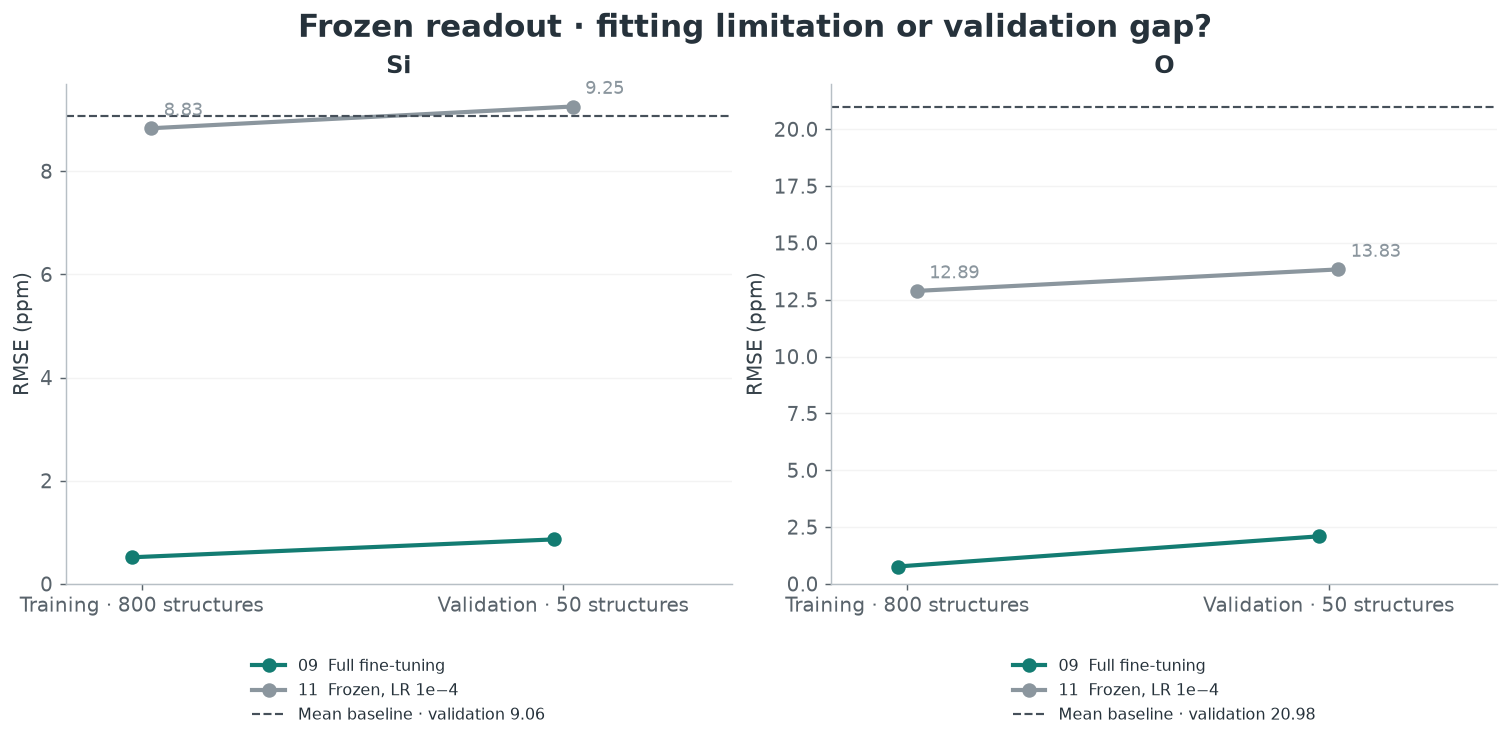

split        Training RMSE  Validation RMSE
run element                                
09  O                0.765            2.093
    Si               0.516            0.862
11  O               12.888           13.834
    Si               8.832            9.254

**Si:** training RMSE 8.832; validation 9.254; mean-baseline validation 9.063 ppm. Frozen validation is 1.02× the constant-baseline error.

**O:** training RMSE 12.888; validation 13.834; mean-baseline validation 20.981 ppm. Frozen validation is 0.66× the constant-baseline error.

In [7]:
gap_figure(metrics, ['09','11'], 'Frozen readout · fitting limitation or validation gap?', OUTPUT, '01-training-validation-gap')
for el in ['Si','O']:
    train=value(metrics,'11',el,split='train'); valid=value(metrics,'11',el); baseline=value(metrics,'mean',el)
    display(Markdown(f'**{el}:** training RMSE {train:.3f}; validation {valid:.3f}; mean-baseline validation {baseline:.3f} ppm. Frozen validation is {valid/baseline:.2f}× the constant-baseline error.'))

## 2 · What does the frozen head actually predict?
All validation sites are shown against the identity line with equal axes. A compressed or biased prediction range reveals a failure mode that a single loss number hides. Si and O are kept separate.

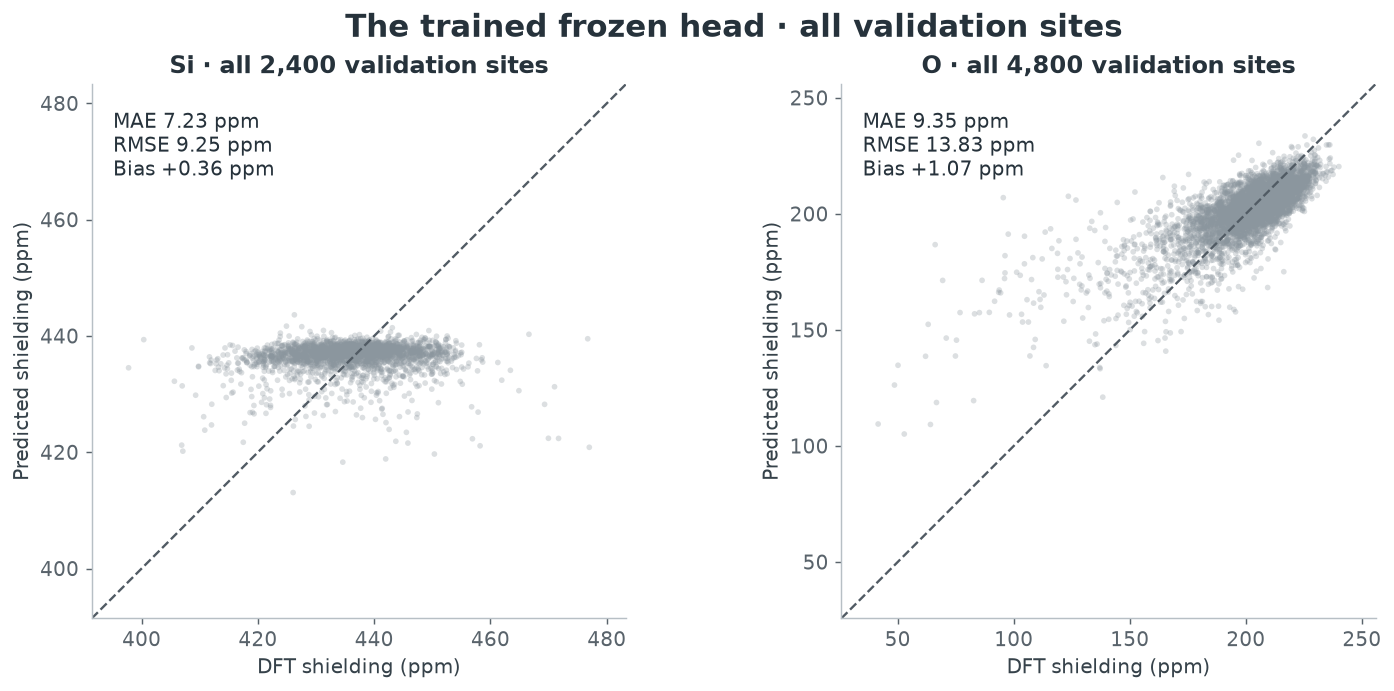

In [8]:
parity_figure(sites, '11', 'The trained frozen head · all validation sites', OUTPUT, '02-frozen-parity')

**Interpretation / next step.** This result alone cannot prove that 132 parameters are inherently insufficient or that E/F features are useless. The selected checkpoint is at the run limit, so convergence is unproven. First optimise the existing head on cached frozen features to convergence. Then compare directly fitted per-element linear/ridge heads and, if needed, a small nonlinear head. Separate elemental heads are more flexible than the present shared weights times elemental scales: their improvement would not isolate optimisation alone. Before future training, guard custom export/logging callbacks against sanity validation (or explicitly disable that preliminary validation). This evaluation diagnoses the issue without changing the training code or checkpoints.

In [9]:
metrics[metrics.run.isin(['09', '11', '11-export', 'mean'])].to_csv(OUTPUT / 'metrics.csv', index=False)
provenance[provenance.run.isin(['09', '11', '11-export', 'mean'])].to_csv(OUTPUT / 'provenance.csv', index=False)
(OUTPUT / 'evaluation-manifest.json').write_text(json.dumps(manifest, indent=2))
assert len(list(OUTPUT.glob('*.png'))) == 2
print('Saved two figures as PNG/PDF, metric tables and provenance.')

**Scope.** Absolute DFT isotropic shielding in ppm; no experimental referencing. Every metric is unweighted and split by element. These 50 validation structures selected the checkpoints; they are development results, not an independent test. Paired 95% intervals use 4,000 whole-structure bootstrap resamples and assume independent structures. They do not cover seed variability, model selection or unresolved trajectory dependence. All runs use seed 42; no new training or test-set evaluation occurs here.

**Reproducibility.** The setup verifies dataset, configuration and checkpoint hashes before using the shared prediction cache. `scalar_transfer_evaluate.py` regenerates it from train/validation data if absent. The shared helper `scalar_transfer_review.py` renders the figures. Use the project's `.venv` kernel; keep these helpers beside the notebooks. Full epoch histories were not included in the transferred results, so no learning curves or claims of convergence are fabricated.